PROJECT EVERETT V6.2 | Classical Skip Ablation on Delaney (ESOL)


--- Training Hybrid QML [WITH Classical Skip] ---
Epoch 20/80 | Train MSE: 0.1312 | Val MSE: 0.1749
Epoch 40/80 | Train MSE: 0.1075 | Val MSE: 0.1747
Epoch 60/80 | Train MSE: 0.1122 | Val MSE: 0.1737
Epoch 80/80 | Train MSE: 0.1012 | Val MSE: 0.1702

--- Training Hybrid QML [QUANTUM-ONLY (Skip Disabled)] ---
Epoch 20/80 | Train MSE: 0.3076 | Val MSE: 0.3685
Epoch 40/80 | Train MSE: 0.2943 | Val MSE: 0.3464
Epoch 60/80 | Train MSE: 0.2925 | Val MSE: 0.3480
Epoch 80/80 | Train MSE: 0.2830 | Val MSE: 0.3412

ABLATION BENCHMARK SUMMARY (UNSEEN TEST SET)
                    Model  R2 (Test)  RMSE [log(mol/L)]  Time (s)
   Hybrid QML (With Skip)     0.8449             0.8562     59.17
Hybrid QML (Quantum-Only)     0.6891             1.2123     57.73
            Classical MLP     0.8515             0.8377      2.05
Random Forest (300 trees)     0.8609             0.8110      1.63



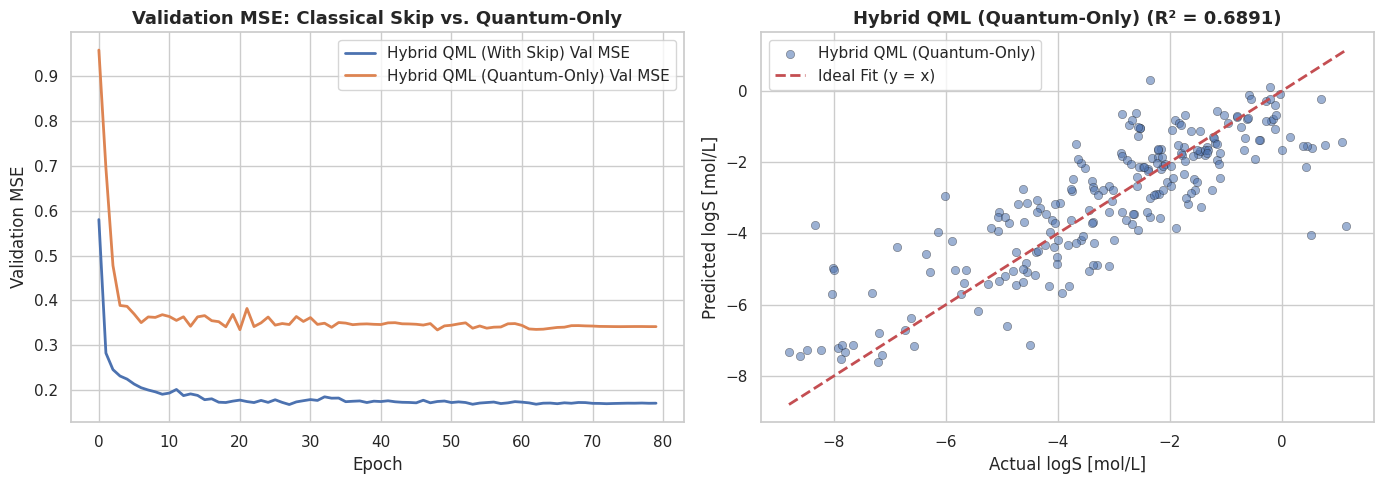

In [10]:
# ==============================================================================
# PROJECT EVERETT V6.2 (Ablation: With vs. Without Classical Skip Connection)
# Author: Katchaw451 | Dataset: DeepChem Delaney (ESOL) Aqueous Solubility
# ==============================================================================

!pip install rdkit pennylane torch matplotlib seaborn scikit-learn pandas -q

import io
import time
import urllib.request
import warnings
import matplotlib.pyplot as plt
import pandas as pd
import pennylane as qml
from pennylane import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Toggle classical skip branch (set to False for quantum-only ablation)
USE_CLASSICAL_SKIP = True
RUN_FULL_ABLATION = True  # Runs both True and False for direct comparison

print("=" * 72)
print("PROJECT EVERETT V6.2 | Classical Skip Ablation on Delaney (ESOL)")
print("=" * 72 + "\n")

# ------------------------------------------------------------------------------
# 1. DATA LOADING, SPLIT & SCALING (NO LEAKAGE)
# ------------------------------------------------------------------------------
url = "https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv"
req = urllib.request.urlopen(url)
data = pd.read_csv(io.StringIO(req.read().decode("utf-8")))

features = []
targets = []

for _, row in data.iterrows():
    mol = Chem.MolFromSmiles(row["smiles"])
    if mol:
        features.append([
            Descriptors.MolWt(mol),
            Descriptors.MolLogP(mol),
            Descriptors.NumHDonors(mol),
            Descriptors.NumHAcceptors(mol),
            Descriptors.TPSA(mol),
            Descriptors.NumRotatableBonds(mol),
            Descriptors.FractionCSP3(mol),
        ])
        targets.append(row["measured log solubility in mols per litre"])

X_raw = np.array(features, dtype=np.float64)
y_raw = np.array(targets, dtype=np.float64)

X_tr_raw, X_te_raw, y_tr_raw, y_te_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=SEED
)

scaler_x = StandardScaler()
X_tr_scaled = scaler_x.fit_transform(X_tr_raw)
X_te_scaled = scaler_x.transform(X_te_raw)

scaler_y = StandardScaler()
y_tr_scaled = scaler_y.fit_transform(y_tr_raw.reshape(-1, 1)).ravel()
y_te_scaled = scaler_y.transform(y_te_raw.reshape(-1, 1)).ravel()

# Map standardized features smoothly into [-pi/2, pi/2] to avoid phase wrapping
n_qubits = 4
pca = PCA(n_components=n_qubits, random_state=SEED)
X_tr_q_angles = (np.pi / 2.0) * np.tanh(pca.fit_transform(X_tr_scaled))
X_te_q_angles = (np.pi / 2.0) * np.tanh(pca.transform(X_te_scaled))

X_train_q = torch.tensor(X_tr_q_angles, dtype=torch.float32)
X_test_q = torch.tensor(X_te_q_angles, dtype=torch.float32)
X_train_c = torch.tensor(X_tr_scaled, dtype=torch.float32)
X_test_c = torch.tensor(X_te_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_tr_scaled, dtype=torch.float32).unsqueeze(1)
y_test_t = torch.tensor(y_te_scaled, dtype=torch.float32).unsqueeze(1)

BATCH_SIZE = 64

# ------------------------------------------------------------------------------
# 2. QUANTUM CIRCUIT & ABLATION-READY HYBRID ARCHITECTURE
# ------------------------------------------------------------------------------
n_layers = 3
dev = qml.device("default.qubit", wires=n_qubits)


@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    for layer in range(n_layers):
        qml.AngleEmbedding(features=inputs, wires=range(n_qubits), rotation="Y")
        qml.StronglyEntanglingLayers(weights=weights[layer : layer + 1], wires=range(n_qubits))
        qml.AngleEmbedding(features=inputs, wires=range(n_qubits), rotation="Z")
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]


weight_shapes = {"weights": (n_layers, n_qubits, 3)}


class ImprovedHybridSolubilityNet(nn.Module):
    def __init__(self, n_qubits=4, n_classical_features=7, use_classical_skip=True):
        super().__init__()
        self.use_classical_skip = use_classical_skip
        self.qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)

        skip_dim = 4 if use_classical_skip else 0
        self.classical_skip = nn.Linear(n_classical_features, 4) if use_classical_skip else None

        self.head = nn.Sequential(
            nn.Linear(n_qubits + skip_dim, 16),
            nn.SiLU(),
            nn.Dropout(p=0.1),
            nn.Linear(16, 1),
        )

    def forward(self, x_q, x_c=None):
        q_out = self.qlayer(x_q)
        if self.use_classical_skip:
            if x_c is None:
                raise ValueError("Classical features x_c are required when use_classical_skip=True.")
            c_skip = torch.tanh(self.classical_skip(x_c))
            features_in = torch.cat([q_out, c_skip], dim=-1)
        else:
            # Quantum circuit alone: only VQC expectation values feed the head
            features_in = q_out
        return self.head(features_in)


class ClassicalMLP(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 16),
            nn.SiLU(),
            nn.Dropout(p=0.1),
            nn.Linear(16, 8),
            nn.SiLU(),
            nn.Linear(8, 1),
        )

    def forward(self, x):
        return self.net(x)


def train_hybrid_variant(use_skip, epochs=80, seed=SEED):
    torch.manual_seed(seed)
    np.random.seed(seed)

    loader = DataLoader(
        TensorDataset(X_train_q, X_train_c, y_train_t),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )

    model = ImprovedHybridSolubilityNet(
        n_qubits=n_qubits,
        n_classical_features=X_train_c.shape[1],
        use_classical_skip=use_skip,
    )

    param_groups = [
        {"params": model.qlayer.parameters(), "lr": 0.04, "weight_decay": 1e-4},
        {"params": model.head.parameters(), "lr": 0.008, "weight_decay": 1e-4},
    ]
    if use_skip and model.classical_skip is not None:
        param_groups.append(
            {"params": model.classical_skip.parameters(), "lr": 0.008, "weight_decay": 1e-4}
        )

    optimizer = torch.optim.AdamW(param_groups)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-4)
    criterion = nn.MSELoss()

    train_losses, val_losses = [], []
    start_time = time.time()

    mode_label = "WITH Classical Skip" if use_skip else "QUANTUM-ONLY (Skip Disabled)"
    print(f"\n--- Training Hybrid QML [{mode_label}] ---")

    for epoch in range(epochs):
        model.train()
        batch_losses = []
        for bx_q, bx_c, by in loader:
            optimizer.zero_grad()
            preds = model(bx_q, bx_c)
            loss = criterion(preds, by)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())

        scheduler.step()
        mean_train = float(np.mean(batch_losses))
        train_losses.append(mean_train)

        model.eval()
        with torch.no_grad():
            val_preds = model(X_test_q, X_test_c)
            val_loss = criterion(val_preds, y_test_t).item()
        val_losses.append(val_loss)

        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch+1:02d}/{epochs} | Train MSE: {mean_train:.4f} | Val MSE: {val_loss:.4f}")

    elapsed = time.time() - start_time
    model.eval()
    with torch.no_grad():
        preds_scaled = model(X_test_q, X_test_c).numpy().ravel()
    preds_real = scaler_y.inverse_transform(preds_scaled.reshape(-1, 1)).ravel()

    return {
        "label": f"Hybrid QML ({'With Skip' if use_skip else 'Quantum-Only'})",
        "preds_real": preds_real,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "elapsed": elapsed,
    }


# ------------------------------------------------------------------------------
# 3. RUN ABLATION & CLASSICAL BASELINES
# ------------------------------------------------------------------------------
epochs = 80
hybrid_runs = []

if RUN_FULL_ABLATION:
    hybrid_runs.append(train_hybrid_variant(use_skip=True, epochs=epochs, seed=SEED))
    hybrid_runs.append(train_hybrid_variant(use_skip=False, epochs=epochs, seed=SEED))
else:
    hybrid_runs.append(train_hybrid_variant(use_skip=USE_CLASSICAL_SKIP, epochs=epochs, seed=SEED))

# Classical MLP baseline
torch.manual_seed(SEED)
np.random.seed(SEED)
mlp_model = ClassicalMLP(in_features=X_train_c.shape[1])
mlp_opt = torch.optim.AdamW(mlp_model.parameters(), lr=0.01, weight_decay=1e-4)
mlp_loader = DataLoader(
    TensorDataset(X_train_c, y_train_t),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
criterion = nn.MSELoss()

mlp_start = time.time()
for _ in range(epochs):
    mlp_model.train()
    for bx_c, by in mlp_loader:
        mlp_opt.zero_grad()
        loss = criterion(mlp_model(bx_c), by)
        loss.backward()
        mlp_opt.step()
mlp_time = time.time() - mlp_start

mlp_model.eval()
with torch.no_grad():
    mlp_preds_scaled = mlp_model(X_test_c).numpy().ravel()
mlp_preds_real = scaler_y.inverse_transform(mlp_preds_scaled.reshape(-1, 1)).ravel()

# Random Forest baseline
rf_start = time.time()
rf_model = RandomForestRegressor(n_estimators=300, random_state=SEED)
rf_model.fit(X_tr_scaled, y_tr_raw)
rf_preds_real = rf_model.predict(X_te_scaled)
rf_time = time.time() - rf_start


def summarize(name, y_true, y_pred, elapsed):
    return {
        "Model": name,
        "R2 (Test)": round(float(r2_score(y_true, y_pred)), 4),
        "RMSE [log(mol/L)]": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 4),
        "Time (s)": round(float(elapsed), 2),
    }


rows = [
    summarize(run["label"], y_te_raw, run["preds_real"], run["elapsed"])
    for run in hybrid_runs
]
rows.append(summarize("Classical MLP", y_te_raw, mlp_preds_real, mlp_time))
rows.append(summarize("Random Forest (300 trees)", y_te_raw, rf_preds_real, rf_time))

ablation_df = pd.DataFrame(rows)

print("\n" + "=" * 72)
print("ABLATION BENCHMARK SUMMARY (UNSEEN TEST SET)")
print("=" * 72)
print(ablation_df.to_string(index=False))
print("=" * 72 + "\n")

# ------------------------------------------------------------------------------
# 4. ABLATION VISUALIZATION
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for run in hybrid_runs:
    axes[0].plot(run["val_losses"], label=f"{run['label']} Val MSE", linewidth=2)
axes[0].set_title("Validation MSE: Classical Skip vs. Quantum-Only", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation MSE")
axes[0].legend()

q_only_run = next((r for r in hybrid_runs if "Quantum-Only" in r["label"]), hybrid_runs[0])
q_r2 = r2_score(y_te_raw, q_only_run["preds_real"])
axes[1].scatter(
    y_te_raw, q_only_run["preds_real"], alpha=0.55, edgecolors="k", linewidth=0.4, label=q_only_run["label"]
)
low = min(y_te_raw.min(), q_only_run["preds_real"].min())
high = max(y_te_raw.max(), q_only_run["preds_real"].max())
axes[1].plot([low, high], [low, high], "r--", linewidth=2, label="Ideal Fit (y = x)")
axes[1].set_title(f"{q_only_run['label']} (R² = {q_r2:.4f})", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Actual logS [mol/L]")
axes[1].set_ylabel("Predicted logS [mol/L]")
axes[1].legend()

plt.tight_layout()
plt.show()